# Probabilistic robotics lab: tracking a moving vehicle

## Setup — provided code

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
plt.rcParams["figure.dpi"] = 110
print("Imports OK:", "NumPy", np.__version__, "| pandas", pd.__version__)

Imports OK: NumPy 2.5.4 | pandas 3.1.0


## The setting

A vehicle moves along a straight line. Its state is

$$
x_t=\begin{bmatrix}p_t\\v_t\end{bmatrix},
$$

where position $p_t$ is in metres and velocity $v_t$ is in metres per second. This is **one-dimensional movement with a two-component state**.

In Tasks 1–3 the sensor measures position, not velocity. The filter assumes

$$
x_t=F x_{t-1}+w_t,\qquad
F=\begin{bmatrix}1&\Delta t\\0&1\end{bmatrix},\qquad
w_t\sim\mathcal N(0,Q),
$$

$$
z_t=H x_t+e_t,\qquad H=\begin{bmatrix}1&0\end{bmatrix},\qquad
e_t\sim\mathcal N(0,R).
$$

Errors are independent across time, and process and sensor errors are independent. Here $R$ is a **scalar variance** because there is one measurement per step.

The simulated vehicle sometimes accelerates. Those accelerations are **not given to the filter**: its constant-velocity model is an approximation during those periods.

### Data — provided code

120 time points: steps **0–119**, one second apart. `acceleration[t]` is nonzero for steps 30–39 and 75–84. Position and velocity disturbances have standard deviations 0.2 m and 0.1 m/s; position-sensor noise has standard deviation 2 m. `truth` is for plots and evaluation only — **never used inside a filter.**

In [2]:
rng = np.random.default_rng(SEED)
dt = 1.0
n_steps = 120
time = np.arange(n_steps) * dt

acceleration = np.zeros(n_steps)
acceleration[30:40] = 0.18
acceleration[75:85] = -0.12

truth = np.zeros((n_steps, 2))
truth[0] = [10.0, 1.0]
for t in range(1, n_steps):
    p, v = truth[t - 1]
    a = acceleration[t]
    truth[t, 0] = p + v * dt + 0.5 * a * dt**2 + rng.normal(0, 0.2)
    truth[t, 1] = v + a * dt + rng.normal(0, 0.1)

sensor_sd = 2.0
z_position = truth[:, 0] + rng.normal(0, sensor_sd, n_steps)

data = pd.DataFrame({
    "time (s)": time,
    "true position (m)": truth[:, 0],
    "true velocity (m/s)": truth[:, 1],
    "position reading (m)": z_position,
})
display(data.head())

,time (s),true position (m),true velocity (m/s),position reading (m)
0,0.0,10.000000,1.000000,7.875171
1,1.0,11.060943,0.896002,10.002065
2,2.0,12.107035,0.990058,10.353314
3,3.0,12.706886,0.859840,12.518361
4,4.0,13.592294,0.828216,10.076838


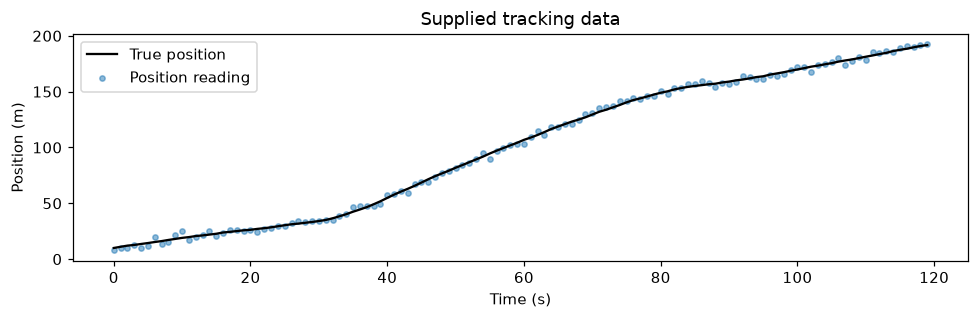

In [3]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(time, truth[:, 0], color="black", label="True position")
ax.scatter(time, z_position, s=12, alpha=0.5, label="Position reading")
ax.set(xlabel="Time (s)", ylabel="Position (m)", title="Supplied tracking data")
ax.legend()
plt.tight_layout()
plt.show()

## Task 1 — implement and evaluate the Kalman filter

**Question:** Can position readings help us estimate both position and velocity?

### 1A. The two update functions

$\mu$ is the estimated state mean and $P$ its covariance. The bar denotes the prediction **before** the current reading:

$$
\bar\mu_t=F\mu_{t-1},\qquad \bar P_t=FP_{t-1}F^T+Q.
$$

Correction for the position sensor:

$$
\nu_t=z_t-H\bar\mu_t,\quad S_t=H\bar P_tH^T+R,\quad
K_t=\frac{\bar P_t H^T}{S_t},
$$

$$
\mu_t=\bar\mu_t+K_t\nu_t,\qquad
P_t=\bar P_t-K_t(H\bar P_t).
$$

$\nu_t$ is the **innovation** (observed minus predicted measurement) and $S_t$ its variance. Shapes: `mu`, `mu_pred`, `H`, `K` are `(2,)`; `P`, `P_pred`, `F`, `Q` are `(2, 2)`; `z`, `R`, innovation and `S` are scalars. The functions return new arrays and do not modify their inputs.

In [4]:
def predict(mu, P, F, Q):
    # Return mu_pred, P_pred.
    mu_pred = F @ mu
    P_pred = F @ P @ F.T + Q
    return mu_pred, P_pred


def correct_position(mu_pred, P_pred, z, H, R):
    # Return mu, P after using the position reading z.
    nu = z - H @ mu_pred                 # innovation (scalar)
    S = H @ P_pred @ H + R               # innovation variance (scalar)
    K = (P_pred @ H) / S                 # Kalman gain, shape (2,)
    mu = mu_pred + K * nu
    P = P_pred - np.outer(K, H @ P_pred)
    return mu, P

### One-step check — provided code

In [5]:
F_check = np.array([[1.0, 1.0], [0.0, 1.0]])
mu_pred, P_pred = predict(
    np.array([0.0, 0.0]), np.diag([1.0, 4.0]), F_check, np.diag([1.0, 1.0])
)
mu_check, P_check = correct_position(
    mu_pred, P_pred, 2.0, np.array([1.0, 0.0]), 4.0
)
assert np.allclose(mu_pred, [0.0, 0.0])
assert np.allclose(P_pred, [[6.0, 4.0], [4.0, 5.0]])
assert np.allclose(mu_check, [1.2, 0.8])
assert np.allclose(P_check, [[2.4, 1.6], [1.6, 3.4]])
print("One-step check passed.")

One-step check passed.


### 1B. The filtering loop

Initial belief and baseline noise settings:

$$
\mu_0=\begin{bmatrix}8\\0\end{bmatrix},\quad
P_0=\operatorname{diag}(9,1),\quad
Q=\operatorname{diag}(0.04,0.01),\quad R=4.
$$

Time convention: row 0 stores the initial belief (`z[0]` is **not** used). For `t = 1 … len(z)-1`: predict once, correct with `z[t]`, store the corrected mean and covariance at row `t`.

In [6]:
mu0 = np.array([8.0, 0.0])
P0 = np.diag([9.0, 1.0])
Q_base = np.diag([0.04, 0.01])
R_base = sensor_sd**2

F = np.array([[1.0, dt],
              [0.0, 1.0]])
H = np.array([1.0, 0.0])

In [7]:
def run_kf(z, F, H, Q, R, mu0, P0):
    # Store the initial belief, then predict and correct at t = 1, 2, ...
    n = len(z)
    means = np.zeros((n, 2))
    covariances = np.zeros((n, 2, 2))
    means[0] = mu0.copy()
    covariances[0] = P0.copy()
    for t in range(1, n):
        mu_pred, P_pred = predict(means[t - 1], covariances[t - 1], F, Q)
        means[t], covariances[t] = correct_position(mu_pred, P_pred, z[t], H, R)
    return means, covariances

### 1C. Evaluate and plot

All numerical evaluations **exclude row 0** (it is the initial belief, not a filtered result). The 95% interval for each component is $\mu_{t,j}\pm1.96\sqrt{P_{t,jj}}$.

In [8]:
def rmse(estimate, actual):
    return np.sqrt(np.mean((estimate - actual)**2))

,Position RMSE (m),Velocity RMSE (m/s)
Raw readings,2.054,NaN
KF,1.356,0.437


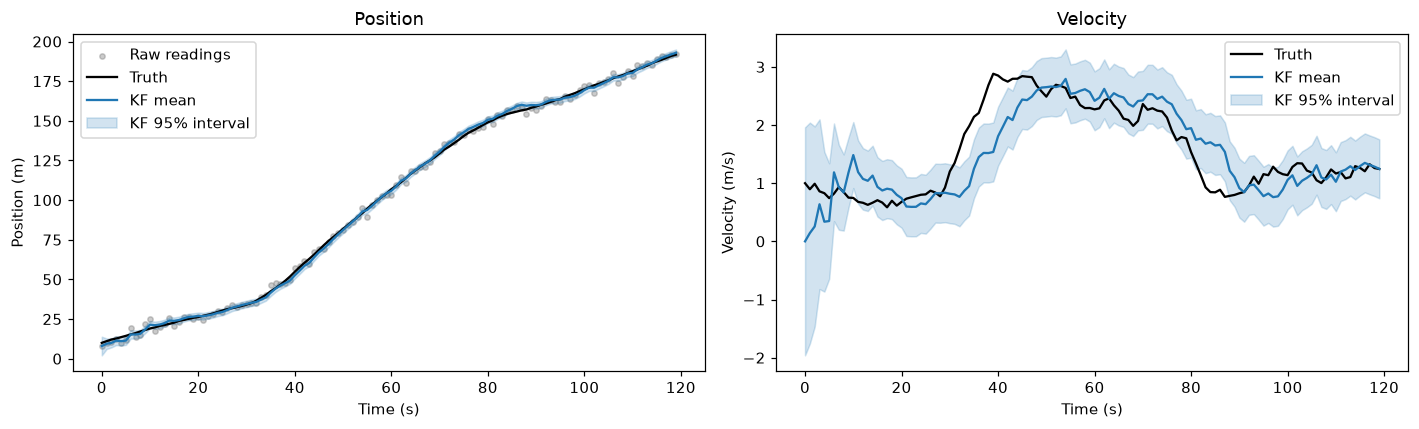

In [9]:
kf_means, kf_covariances = run_kf(z_position, F, H, Q_base, R_base, mu0, P0)

rmse_table = pd.DataFrame({
    "Position RMSE (m)": [rmse(z_position[1:], truth[1:, 0]),
                          rmse(kf_means[1:, 0], truth[1:, 0])],
    "Velocity RMSE (m/s)": [np.nan, rmse(kf_means[1:, 1], truth[1:, 1])],
}, index=["Raw readings", "KF"]).round(3)
display(rmse_table)

sd_p = np.sqrt(kf_covariances[:, 0, 0])
sd_v = np.sqrt(kf_covariances[:, 1, 1])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.scatter(time, z_position, s=12, alpha=0.4, color="tab:gray", label="Raw readings")
ax.plot(time, truth[:, 0], color="black", label="Truth")
ax.plot(time, kf_means[:, 0], color="tab:blue", label="KF mean")
ax.fill_between(time, kf_means[:, 0] - 1.96 * sd_p, kf_means[:, 0] + 1.96 * sd_p,
                alpha=0.2, color="tab:blue", label="KF 95% interval")
ax.set(xlabel="Time (s)", ylabel="Position (m)", title="Position")
ax.legend()

ax = axes[1]
ax.plot(time, truth[:, 1], color="black", label="Truth")
ax.plot(time, kf_means[:, 1], color="tab:blue", label="KF mean")
ax.fill_between(time, kf_means[:, 1] - 1.96 * sd_v, kf_means[:, 1] + 1.96 * sd_v,
                alpha=0.2, color="tab:blue", label="KF 95% interval")
ax.set(xlabel="Time (s)", ylabel="Velocity (m/s)", title="Velocity")
ax.legend()

plt.tight_layout()
plt.show()

In [10]:
# Supporting numbers for the written answers
mp, Pp = predict(kf_means[100], kf_covariances[100], F, Q_base)
K = (Pp @ H) / (H @ Pp @ H + R_base)
print("Predicted P at step 101 (off-diagonal = pos-vel covariance):")
print(Pp.round(3))
print("Gain at step 101 [position, velocity]:", K.round(3))
print("Velocity RMSE, steps 30-39: %.3f m/s" % rmse(kf_means[30:40, 1], truth[30:40, 1]))
print("Mean velocity error, steps 30-39: %.3f m/s" % np.mean(kf_means[30:40, 1] - truth[30:40, 1]))
print("Step 39: KF velocity %.2f vs true %.2f m/s" % (kf_means[39, 1], truth[39, 1]))

Predicted P at step 101 (off-diagonal = pos-vel covariance):
[[1.576 0.236]
 [0.236 0.077]]
Gain at step 101 [position, velocity]: [0.283 0.042]
Velocity RMSE, steps 30-39: 0.923 m/s
Mean velocity error, steps 30-39: -0.883 m/s
Step 39: KF velocity 1.54 vs true 2.88 m/s


### Your answer — Task 1

**1.** Position RMSE is **2.054 m** for the raw readings and **1.356 m** for the KF, so filtering improved position accuracy on this run by about 34%. The KF velocity RMSE is **0.437 m/s** (it cannot be compared with the position values: different units, and the raw readings give no velocity).

**2.** The prediction step $\bar P=FPF^T+Q$ creates a nonzero position–velocity covariance, because the next position depends on the current velocity. The gain $K=\bar P H^T/S$ is the first column of $\bar P$ divided by $S$, so its velocity component is $\bar P_{vp}/S$. Since this covariance is nonzero, a position innovation $\nu$ also changes the velocity estimate by $K_v\nu$, even though velocity is never measured (at step 101 the gain is about [0.28, 0.04]).

**3.** Around steps **30–45**, during the first acceleration (a = 0.18 m/s² for steps 30–39), the velocity estimate follows the truth poorly: at step 39 the KF gives about 1.54 m/s while the true velocity is 2.88 m/s; the velocity RMSE over steps 30–39 is 0.92 m/s with a mean error of −0.88 m/s. The filter assumes constant velocity with small process noise, so it treats the rising velocity as noise and follows it only slowly. The second (smaller, braking) period around 75–85 shows the same lag with opposite sign.